In [5]:
import Bio
print(Bio.__version__)

1.86


# 解析対象
今回はミトコンドリア COX1

理由
- ほぼ全生物にある
- 長さが似ている
- 系統解析の定番

名前	学名
ジュウシマツ	Lonchura striata domestica
キンカチョウ	Taeniopygia guttata
スズメ	Passer montanus
ニワトリ	Gallus gallus
ヒト	Homo sapiens

In [6]:
#Entrez用のメールアドレスを設定
mailadress="ここにメールアドレスを入力"

In [7]:
from Bio import Entrez, SeqIO
from Bio.SeqRecord import SeqRecord
from http.client import IncompleteRead
import time


Entrez.email = mailadress


# ==========================================
# 解析対象種
# ==========================================

SPECIES = [
    "Lonchura striata domestica",       # ジュウシマツ
    "Lonchura leucogastroides",         # ブンチョウ
    "Nymphicus hollandicus",            # オカメインコ
    "Cacatua galerita",                 # キバタン
    "Strigops habroptilus",             # カカポ
    "Apteryx mantelli",                 # キーウィ
    "Psittacus erithacus",              # ヨウム
    "Phasianus colchicus",              # キジ
    "Gallus gallus",                    # ニワトリ
    "Casuarius casuarius",              # ヒクイドリ
    "Dromaius novaehollandiae",         # エミュー
    "Ara chloropterus",                 # ベニコンゴウインコ
    "Passer montanus",                  # スズメ
    "Hirundo rustica",                  # ツバメ
    "Cygnus columbianus",               # コハクチョウ
    "Ardea alba",                       # ダイサギ
    "Egretta garzetta"                  # コサギ
]


# ==========================================
# COX1表記揺れ
# ==========================================

TARGET_NAMES = {
    "COX1",
    "COXI",
    "COI",
    "MT-CO1",
    "CYTOCHROME C OXIDASE SUBUNIT I",
    "CYTOCHROME C OXIDASE SUBUNIT 1"
}


In [8]:
# ==========================================
# NCBI検索
# ==========================================

def search_mito_genome(species):

    query = (
        f'"{species}"[Organism] '
        'AND mitochondrion[Title] '
        'AND complete genome'
    )

    handle = Entrez.esearch(
        db="nucleotide",
        term=query,
        retmax=20
    )

    result = Entrez.read(handle)

    return result["IdList"]



# ==========================================
# GenBank取得
# ==========================================

def get_record(ncbi_id):

    for retry in range(5):

        try:

            handle = Entrez.efetch(
                db="nucleotide",
                id=ncbi_id,
                rettype="gb",
                retmode="text"
            )

            record = SeqIO.read(
                handle,
                "genbank"
            )

            return record


        except IncompleteRead:

            print(
                "Retry",
                retry + 1
            )

            time.sleep(2)


    return None



# ==========================================
# COX1抽出
# ==========================================

def extract_cox1(record):

    for feature in record.features:

        if feature.type != "CDS":
            continue


        names = []


        for key in [
            "gene",
            "product",
            "note"
        ]:

            if key in feature.qualifiers:

                names.extend(
                    [
                        x.upper()
                        for x in feature.qualifiers[key]
                    ]
                )


        for name in names:

            for target in TARGET_NAMES:

                if target in name:


                    seq = feature.location.extract(
                        record.seq
                    )


                    return seq


    return None

# ==========================================
# COX1 QC
# ==========================================

def check_cox1(seq):

    length = len(seq)

    if length < 1400 or length > 1700:
        return False


    protein = seq.translate(
        table=2
    )


    if len(protein) < 450:
        return False


    # 途中停止コドン確認
    if "*" in str(protein[:-1]):
        return False


    return True


# ==========================================
# メイン処理
# ==========================================


for species in SPECIES:


    print("=" * 70)
    print(species)


    ids = search_mito_genome(species)


    if len(ids) == 0:

        print("検索失敗")
        continue



    cox1 = None
    record_ok = None



    for ncbi_id in ids:


        record = get_record(ncbi_id)


        if record is None:
            continue



        print(
            "候補:",
            record.description
        )

        organism = record.annotations.get(
            "organism",
            ""
        )
        
        if species.split()[0] not in organism:
            print("別生物候補")
            continue



        cox1 = extract_cox1(record)

        if cox1 is not None:
        
            if not check_cox1(cox1):
        
                print("COX1 QC失敗")
                cox1 = None
                continue
    

        if cox1 is not None:

            record_ok = record
            break



    if cox1 is None:

        print(
            "COX1取得失敗"
        )

        continue



    print(
        "Genome:",
        len(record_ok.seq)
    )

    print(
        "COX1 length:",
        len(cox1)
    )


    filename = species.replace(
        " ",
        "_"
    )
    
    accession = record_ok.id.replace(".", "_")
    
    
    fasta_record = SeqRecord(
        cox1,
        id=f"{filename}_{accession}_COX1",
        description=""
    )



    SeqIO.write(
        fasta_record,
        f"{filename}_COX1.fasta",
        "fasta"
    )


    print(
        "保存:",
        f"{filename}_COX1.fasta"
    )


    time.sleep(1)



print("\n完了")

Lonchura striata domestica
候補: Lonchura striata mitochondrion, complete genome
Genome: 16813
COX1 length: 1551
保存: Lonchura_striata_domestica_COX1.fasta
Lonchura leucogastroides
検索失敗
Nymphicus hollandicus
候補: Nymphicus hollandicus mitochondrion, complete genome
Genome: 16781
COX1 length: 1548
保存: Nymphicus_hollandicus_COX1.fasta
Cacatua galerita
候補: Cacatua galerita mitochondrion, complete genome
Genome: 18900
COX1 length: 1548
保存: Cacatua_galerita_COX1.fasta
Strigops habroptilus
候補: Strigops habroptilus mitochondrion, complete genome
Genome: 15599
COX1 length: 1548
保存: Strigops_habroptilus_COX1.fasta
Apteryx mantelli
候補: Apteryx mantelli isolate bAptMan1 mitochondrion, complete sequence, whole genome shotgun sequence
候補: Apteryx mantelli mitochondrion, partial genome
Genome: 12269
COX1 length: 1551
保存: Apteryx_mantelli_COX1.fasta
Psittacus erithacus
候補: Psittacus erithacus mitochondrion, complete genome
Genome: 17962
COX1 length: 1548
保存: Psittacus_erithacus_COX1.fasta
Phasianus colch

In [9]:
from pathlib import Path

records = []

for sp in SPECIES:

    file = Path(f"{sp.replace(' ', '_')}_COX1.fasta")

    if not file.exists():
        print(f"スキップ: {file}")
        continue

    record = SeqIO.read(file, "fasta")
    records.append(record)

    print(record.id)

SeqIO.write(records, "all_cox1.fasta", "fasta")

print(f"\n{len(records)}種を保存しました。")

Lonchura_striata_domestica_NC_029475_1_COX1
スキップ: Lonchura_leucogastroides_COX1.fasta
Nymphicus_hollandicus_NC_015192_1_COX1
Cacatua_galerita_NC_059711_1_COX1
Strigops_habroptilus_NC_005931_1_COX1
Apteryx_mantelli_AY016010_1_COX1
Psittacus_erithacus_NC_027847_1_COX1
Phasianus_colchicus_PQ474154_1_COX1
Gallus_gallus_PZ672148_1_COX1
Casuarius_casuarius_NC_002778_2_COX1
Dromaius_novaehollandiae_NC_002784_1_COX1
Ara_chloropterus_PQ167822_1_COX1
Passer_montanus_NC_024821_1_COX1
Hirundo_rustica_NC_050297_1_COX1
Cygnus_columbianus_NC_007691_1_COX1
スキップ: Ardea_alba_COX1.fasta
Egretta_garzetta_OR757053_1_COX1

15種を保存しました。


# マルチプルアラインメントをして種間のミトコンドリアCOX1遺伝子距離行列を作成

In [10]:
records = []
missing = []

for sp in SPECIES:

    file = Path(f"{sp.replace(' ', '_')}_COX1.fasta")

    if file.exists():

        record = SeqIO.read(file, "fasta")
        records.append(record)

        print(f"✓ {record.id}")

    else:

        missing.append(sp)

print()
print(f"取得成功 : {len(records)}")
print(f"取得失敗 : {len(missing)}")

if missing:
    print("\n取得できなかった生物")
    for sp in missing:
        print(" -", sp)

✓ Lonchura_striata_domestica_NC_029475_1_COX1
✓ Nymphicus_hollandicus_NC_015192_1_COX1
✓ Cacatua_galerita_NC_059711_1_COX1
✓ Strigops_habroptilus_NC_005931_1_COX1
✓ Apteryx_mantelli_AY016010_1_COX1
✓ Psittacus_erithacus_NC_027847_1_COX1
✓ Phasianus_colchicus_PQ474154_1_COX1
✓ Gallus_gallus_PZ672148_1_COX1
✓ Casuarius_casuarius_NC_002778_2_COX1
✓ Dromaius_novaehollandiae_NC_002784_1_COX1
✓ Ara_chloropterus_PQ167822_1_COX1
✓ Passer_montanus_NC_024821_1_COX1
✓ Hirundo_rustica_NC_050297_1_COX1
✓ Cygnus_columbianus_NC_007691_1_COX1
✓ Egretta_garzetta_OR757053_1_COX1

取得成功 : 15
取得失敗 : 2

取得できなかった生物
 - Lonchura leucogastroides
 - Ardea alba


In [11]:
from Bio import Align

aligner = Align.PairwiseAligner()

aligner.mode = "global"

aligner.match_score = 1
aligner.mismatch_score = -1
aligner.open_gap_score = -5
aligner.extend_gap_score = -1



import numpy as np

n = len(records)

dist = np.zeros((n, n))

for i in range(n):
    for j in range(i + 1, n):

        score = aligner.score(records[i].seq, records[j].seq)

        # 仮の距離
        d = 1 - score / max(len(records[i]), len(records[j]))

        dist[i, j] = d
        dist[j, i] = d

print(dist)

[[0.         0.31850419 0.32108317 0.32624113 0.33526757 0.31850419
  0.36363636 0.344294   0.35976789 0.35718891 0.32237266 0.24629271
  0.30956969 0.35203095 0.26434558]
 [0.31850419 0.         0.21705426 0.25064599 0.36879433 0.23385013
  0.33268859 0.33010961 0.35460993 0.34945197 0.25839793 0.30689877
  0.34682081 0.32753063 0.30947776]
 [0.32108317 0.21705426 0.         0.28552972 0.35332044 0.25710594
  0.35203095 0.32753063 0.344294   0.35332044 0.25581395 0.33397808
  0.36223507 0.34816248 0.33268859]
 [0.32624113 0.25064599 0.28552972 0.         0.35074146 0.28165375
  0.34558349 0.36234687 0.33397808 0.3313991  0.27777778 0.33913604
  0.37251124 0.3584784  0.34042553]
 [0.33526757 0.36879433 0.35332044 0.35074146 0.         0.36750484
  0.36492585 0.35460993 0.3030303  0.27337202 0.37137331 0.36105738
  0.36480411 0.3726628  0.35460993]
 [0.31850419 0.23385013 0.25710594 0.28165375 0.36750484 0.
  0.35718891 0.33010961 0.35074146 0.34945197 0.25322997 0.32366215
  0.3519589 

                                             Lonchura_striata_domestica_NC_029475_1_COX1  \
Lonchura_striata_domestica_NC_029475_1_COX1                                        0.000   
Nymphicus_hollandicus_NC_015192_1_COX1                                             0.319   
Cacatua_galerita_NC_059711_1_COX1                                                  0.321   
Strigops_habroptilus_NC_005931_1_COX1                                              0.326   
Apteryx_mantelli_AY016010_1_COX1                                                   0.335   
Psittacus_erithacus_NC_027847_1_COX1                                               0.319   
Phasianus_colchicus_PQ474154_1_COX1                                                0.364   
Gallus_gallus_PZ672148_1_COX1                                                      0.344   
Casuarius_casuarius_NC_002778_2_COX1                                               0.360   
Dromaius_novaehollandiae_NC_002784_1_COX1                                       

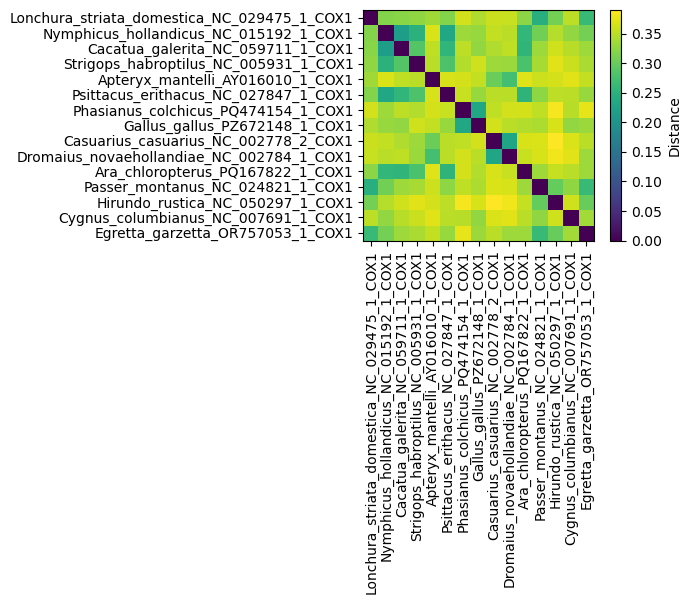

In [12]:
import pandas as pd

# 種名を取得
names = [record.id for record in records]

# DataFrame化
df = pd.DataFrame(
    dist,
    index=names,
    columns=names
)

print(df.round(3))


import matplotlib.pyplot as plt

plt.figure(figsize=(7,6))

plt.imshow(dist)

plt.xticks(range(n), names, rotation=90)
plt.yticks(range(n), names)

plt.colorbar(label="Distance")

plt.tight_layout()
plt.show()

# 系統樹作成

UPFMA法…biopython

近隣結合(NJ法…biopython

最大節約(MP)法…MUSCLE.exeを利用して、マルチプルアラインメント後に最小置換となる樹形を探索

In [13]:
### 距離行列をBiopython形式へ ###

from Bio.Phylo.TreeConstruction import DistanceMatrix

names = [r.id for r in records]

# 下三角行列を作る
matrix = []
for i in range(len(names)):
    matrix.append(list(dist[i][:i+1]))

dm = DistanceMatrix(names, matrix)

In [14]:
### UPGMA法 ###

from Bio.Phylo.TreeConstruction import DistanceTreeConstructor
from Bio import Phylo

constructor = DistanceTreeConstructor()

tree_upgma = constructor.upgma(dm)

Phylo.draw_ascii(tree_upgma)

              ______________________ Dromaius_novaehollandiae_NC_002784_1_...
         ____|
  ______|    |______________________ Casuarius_casuarius_NC_002778_2_COX1
 |      |
 |      |___________________________ Apteryx_mantelli_AY016010_1_COX1
 |
 |  ________________________________ Cygnus_columbianus_NC_007691_1_COX1
_|_|
 | |          ______________________ Gallus_gallus_PZ672148_1_COX1
 | |_________|
 |           |______________________ Phasianus_colchicus_PQ474154_1_COX1
 |
 |        __________________________ Strigops_habroptilus_NC_005931_1_COX1
 | ______|
 ||      |  ________________________ Ara_chloropterus_PQ167822_1_COX1
 ||      |_|
 ||        | _______________________ Psittacus_erithacus_NC_027847_1_COX1
 ||        ||
 ||         |  _____________________ Cacatua_galerita_NC_059711_1_COX1
  |         |_|
  |           |_____________________ Nymphicus_hollandicus_NC_015192_1_COX1
  |
  |    _____________________________ Hirundo_rustica_NC_050297_1_COX1
  |___|
      |    _

In [15]:
### NJ法 ###
tree_nj = constructor.nj(dm)

Phylo.draw_ascii(tree_nj)

   ____________________ Strigops_habroptilus_NC_005931_1_COX1
  |
  |       ________________________ Cygnus_columbianus_NC_007691_1_COX1
  |     _|
  |    | |       ________________ Gallus_gallus_PZ672148_1_COX1
 ,|    | |______|
 ||    |        |__________________ Phasianus_colchicus_PQ474154_1_COX1
 ||    |
 ||    |           ________________ Dromaius_novaehollandiae_NC_002784_1_...
 ||    |       ___|
 ||____|______|   |________________ Casuarius_casuarius_NC_002778_2_COX1
 |     |      |
 |     |      |_____________________ Apteryx_mantelli_AY016010_1_COX1
 |     |
 |     |    _______________________ Hirundo_rustica_NC_050297_1_COX1
 |     |___|
 |         |___________________ Egretta_garzetta_OR757053_1_COX1
 |         |
 |         |  _________________ Passer_montanus_NC_024821_1_COX1
 |         |_|
 |           |_________________ Lonchura_striata_domestica_NC_029475_...
_|
 |  ________________ Cacatua_galerita_NC_059711_1_COX1
 |_|
 | |______________ Nymphicus_hollandicus_NC_0151


muscle 5.3.linux64 [d9725ac]  14.3Gb RAM, 8 cores
Built Nov 10 2024 22:58:59
(C) Copyright 2004-2021 Robert C. Edgar.
https://drive5.com

[align all_cox1.fasta]
Input: 15 seqs, avg length 1550, max 1557, min 1548

00:00 4.7Mb   100.0% Derep 15 uniques, 0 dupes
00:00 4.7Mb  CPU has 8 cores, running 8 threads
00:10 1.7Gb   100.0% Calc posteriors
00:11 553Mb   100.0% UPGMA5         
00:11 553Mb   100.0% Consistency (1/2)
00:11 553Mb   100.0% Consistency (2/2)
00:12 553Mb   100.0% Refining         


Alignment with 15 rows and 1557 columns
GTGACCTTCATCAACCGATGATTATTCTCAACTAACCATAAAGA...AGG Phasianus_colchicus_PQ474154_1_COX1
GTGACATTCATTACTCGATGATTTTTTTCTACAAACCACAAAGA...AGG Dromaius_novaehollandiae_NC_002784_1_COX1
GTGACCTT---AAATCGATGATTATTCTCCACTAACCATAAAGA...AGG Strigops_habroptilus_NC_005931_1_COX1
GTGACATTCATTAACCGATGATTATTTTCAACCAACCACAAAGA...AGG Lonchura_striata_domestica_NC_029475_1_COX1
GTGACCTTTATTACTCGATGACTCTTCTCAACTAACCATAAAGA...AGG Apteryx_mantelli_AY016010_1_COX1
GTGACCCT---AAATCGATGACTATTCTCAACCAACCACAAAGA...AGG Psittacus_erithacus_NC_027847_1_COX1
GTGACATTCATCAACCGATGACTATTCTCAACCAACCACAAAGA...AGG Passer_montanus_NC_024821_1_COX1
GTGACATTCATTAATCGATGACTATTCTCAACAAACCACAAAGA...AGG Hirundo_rustica_NC_050297_1_COX1
GTGACCTTCATCAACCGATGACTATTTTCCACTAACCATAAAGA...AGG Cygnus_columbianus_NC_007691_1_COX1
GTGACCTT---AAATCGATGACTATTCTCAACCAATCACAAAGA...AGG Cacatua_galerita_NC_059711_1_COX1
GTGACCCT---AAATCGATGATTATTCTCAACCAACCACAAAGA...AGG Ara_chloropterus_PQ167822_1_COX1


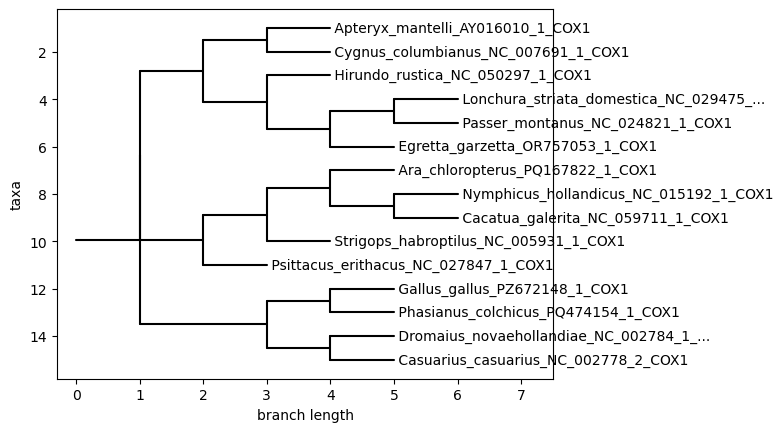

=== Initial ===
                               _____ Psittacus_erithacus_NC_027847_1_COX1
                         _____|
                   _____|     |_____ Passer_montanus_NC_024821_1_COX1
                  |     |
             _____|     |_____ Strigops_habroptilus_NC_005931_1_COX1
            |     |
            |     |      _____ Hirundo_rustica_NC_050297_1_COX1
            |     |_____|
       _____|           |_____ Apteryx_mantelli_AY016010_1_COX1
      |     |
      |     |            _____ Cacatua_galerita_NC_059711_1_COX1
      |     |      _____|
      |     |_____|     |_____ Egretta_garzetta_OR757053_1_COX1
      |           |
      |           |_____ Lonchura_striata_domestica_NC_029475_...
      |
      |      _____ Gallus_gallus_PZ672148_1_COX1
      |_____|
______|     |_____ Dromaius_novaehollandiae_NC_002784_1_...
      |
      |                  _____ Nymphicus_hollandicus_NC_015192_1_COX1
      |            _____|
      |           |     |      _____ Ara_chloropt

In [16]:
### MP法 ###
import subprocess
import random
from io import StringIO
from Bio import Phylo

def generate_random_tree(names):
    """
    ランダムな二分木(Newick)を生成する
    """

    nodes = [f"{name}:1" for name in names]

    while len(nodes) > 1:

        # ランダムに2つ選ぶ
        a = random.choice(nodes)
        nodes.remove(a)

        b = random.choice(nodes)
        nodes.remove(b)

        # 新しい内部ノード
        nodes.append(f"({a},{b}):1")

    return Phylo.read(StringIO(nodes[0] + ";"), "newick")


### 前処理のマルチプルアラインメント（MUSCLE使用） ###
subprocess.run([
    "./muscle-linux-x86.v5.3",
    "-align",
    "all_cox1.fasta",
    "-output",
    "aligned.fasta"
], check=True)

from Bio import AlignIO

alignment = AlignIO.read("aligned.fasta", "fasta")

print(alignment)
print(alignment.get_alignment_length()) #アラインメント後の長さ
for record in alignment: #ギャップの位置確認
    print(record.id)
    print(record.seq[:100])

### MP法で系統樹探索 ###

alignment = AlignIO.read(
    "aligned.fasta",
    "fasta"
)

print(alignment)


from Bio.Phylo.TreeConstruction import *

scorer = ParsimonyScorer()

searcher = NNITreeSearcher(scorer)

from Bio import Phylo
from io import StringIO

names = [record.id for record in alignment]


tree_random = generate_random_tree(names)

constructor = ParsimonyTreeConstructor(
    searcher,
    tree_random
)

tree_mp = constructor.build_tree(alignment)


score = scorer.get_score( #総変異回数スコアを確認
    tree_mp,
    alignment
)
print("変異スコア",score)

Phylo.draw(tree_mp)

initial_score = scorer.get_score(
    tree_random,
    alignment
)

final_score = scorer.get_score(
    tree_mp,
    alignment
)


print("=== Initial ===")
Phylo.draw_ascii(tree_random)

print("=== Final ===")
Phylo.draw_ascii(tree_mp)

print("Initial =", initial_score)
print("Final   =", final_score)

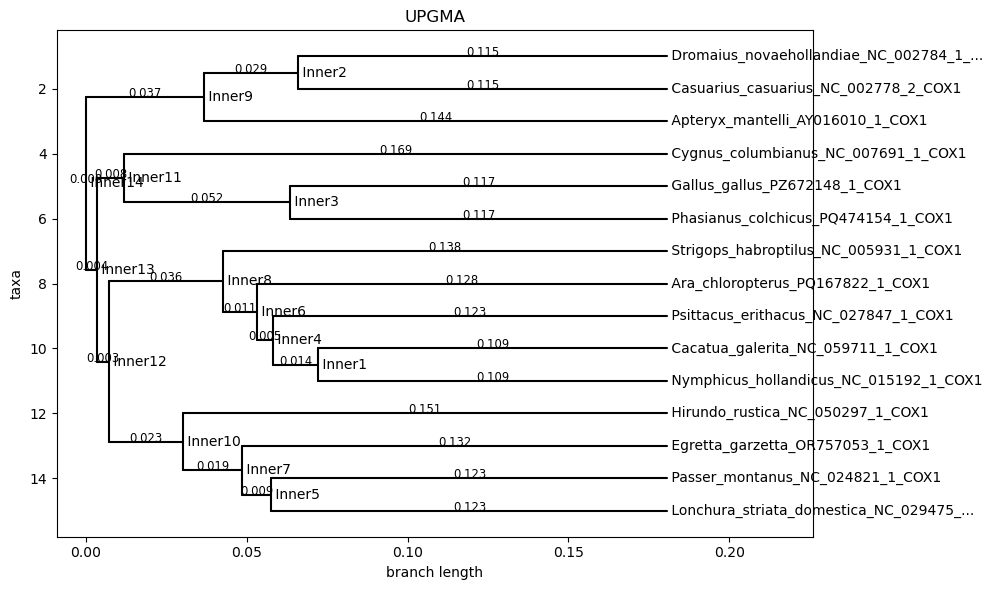

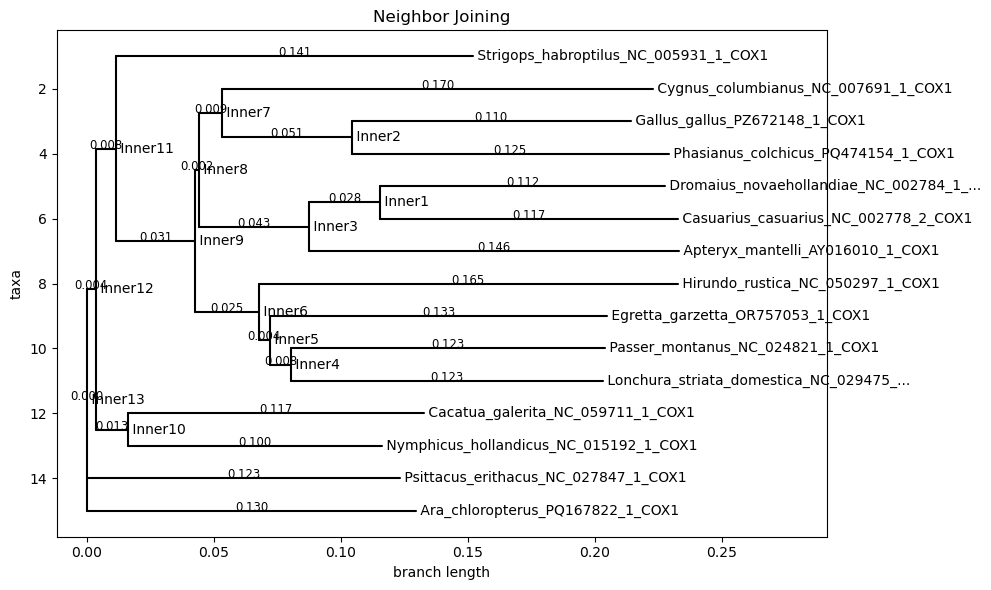

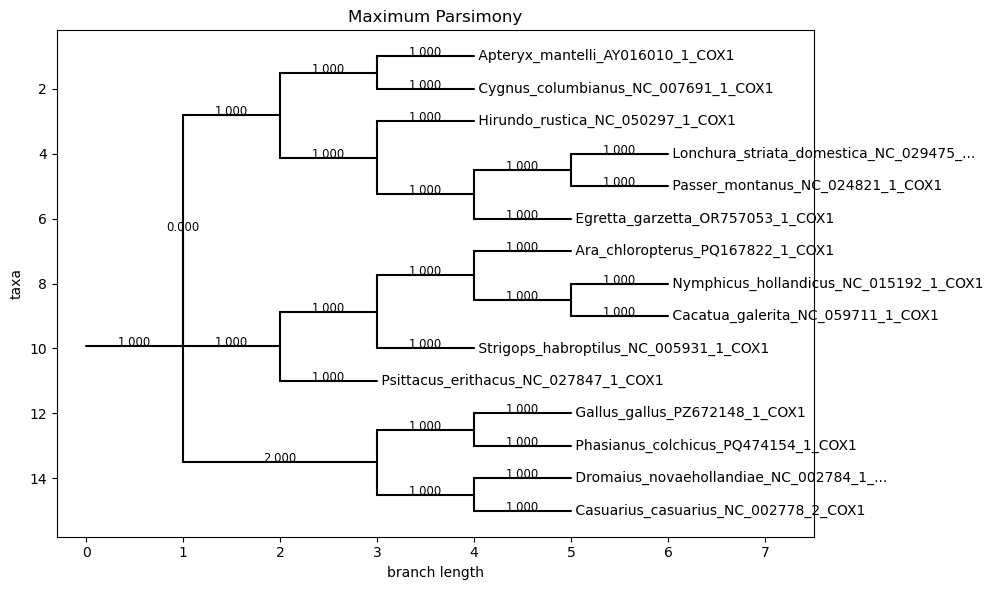

(((Dromaius_novaehollandiae_NC_002784_1_COX1:0.11476,Casuarius_casuarius_NC_002778_2_COX1:0.11476)Inner2:0.02934,Apteryx_mantelli_AY016010_1_COX1:0.14410)Inner9:0.03667,((Cygnus_columbianus_NC_007691_1_COX1:0.16892,(Gallus_gallus_PZ672148_1_COX1:0.11734,Phasianus_colchicus_PQ474154_1_COX1:0.11734)Inner3:0.05158)Inner11:0.00833,((Strigops_habroptilus_NC_005931_1_COX1:0.13816,(Ara_chloropterus_PQ167822_1_COX1:0.12758,(Psittacus_erithacus_NC_027847_1_COX1:0.12274,(Cacatua_galerita_NC_059711_1_COX1:0.10853,Nymphicus_hollandicus_NC_015192_1_COX1:0.10853)Inner1:0.01421)Inner4:0.00484)Inner6:0.01058)Inner8:0.03563,(Hirundo_rustica_NC_050297_1_COX1:0.15077,(Egretta_garzetta_OR757053_1_COX1:0.13217,(Passer_montanus_NC_024821_1_COX1:0.12315,Lonchura_striata_domestica_NC_029475_1_COX1:0.12315)Inner5:0.00903)Inner7:0.01860)Inner10:0.02302)Inner12:0.00346)Inner13:0.00352)Inner14:0.00000;

(((Strigops_habroptilus_NC_005931_1_COX1:0.14062,(((Cygnus_columbianus_NC_007691_1_COX1:0.16955,(Gallus_gallus_

In [17]:
def draw_tree(tree, title):
    fig, ax = plt.subplots(figsize=(10, 6))

    Phylo.draw(
        tree,
        axes=ax,
        do_show=False,
        branch_labels=lambda c: f"{c.branch_length:.3f}"
        if c.branch_length is not None else ""
    )

    ax.set_title(title)
    plt.tight_layout()
    plt.show()


draw_tree(tree_upgma, "UPGMA")
draw_tree(tree_nj, "Neighbor Joining")
draw_tree(tree_mp, "Maximum Parsimony")

### newick形式で構造も出力 ###
Phylo.write(tree_upgma, "upgma.nwk", "newick")
Phylo.write(tree_nj, "nj.nwk", "newick")

print(tree_upgma.format("newick"))
print(tree_nj.format("newick"))

In [18]:
#=======================================================
#RF距離（Robinson–Foulds distance）で系統樹の類似性評価
# →枝分かれ構造が一致している度合
#=======================================================

def get_splits(tree):

    """
    Treeから内部枝のsplit集合を取得
    """

    terminals = tree.get_terminals()

    all_leaves = set(
        t.name for t in terminals
    )

    splits = set()


    for clade in tree.get_nonterminals():

        leaves = set(
            t.name
            for t in clade.get_terminals()
        )

        # 根(root)由来のsplitは除外
        if len(leaves) == len(all_leaves):
            continue

        # 補集合側を小さい方に統一
        other = all_leaves - leaves

        if len(leaves) > len(other):
            leaves = other


        splits.add(
            tuple(sorted(leaves))
        )


    return splits



def robinson_foulds(tree1, tree2):

    split1 = get_splits(tree1)
    split2 = get_splits(tree2)


    difference = (
        split1 - split2
    )


    difference2 = (
        split2 - split1
    )


    rf = len(difference) + len(difference2)


    return rf



rf_NJ_UPGMA = robinson_foulds(
    tree_nj,
    tree_upgma
)


rf_NJ_MP = robinson_foulds(
    tree_nj,
    tree_mp
)


rf_UPGMA_MP = robinson_foulds(
    tree_upgma,
    tree_mp
)


print("NJ vs UPGMA:", rf_NJ_UPGMA)
print("NJ vs MP:", rf_NJ_MP)
print("UPGMA vs MP:", rf_UPGMA_MP)

NJ vs UPGMA: 2
NJ vs MP: 10
UPGMA vs MP: 10


In [19]:
#=======================================================
# Pearson相関で距離行列を比較
# →枝の長さの違いは大きすぎないか？の観点
#=======================================================

from scipy.stats import pearsonr

def tree_distance_matrix(tree):

    terminals = tree.get_terminals()

    names = [
        t.name
        for t in terminals
    ]

    matrix = []

    for a, b in itertools.combinations(terminals, 2):

        d = tree.distance(a, b)

        matrix.append(d)

    return names, np.array(matrix)



names_NJ, distance_matrix_NJ = tree_distance_matrix(tree_nj)

names_UPGMA, distance_matrix_UPGMA = tree_distance_matrix(tree_upgma)



r, p = pearsonr(
    distance_matrix_NJ,
    distance_matrix_UPGMA
)

print(r)

0.5110840184350108


# ここから下は問題解決用


In [61]:
for record in alignment:
    print(record.id, len(record.seq))

Apteryx_mantelli_AY016010_1_COX1 1557
Ara_chloropterus_PQ167822_1_COX1 1557
Cacatua_galerita_NC_059711_1_COX1 1557
Casuarius_casuarius_NC_002778_2_COX1 1557
Cygnus_columbianus_NC_007691_1_COX1 1557
Dromaius_novaehollandiae_NC_002784_1_COX1 1557
Egretta_garzetta_OR757053_1_COX1 1557
Gallus_gallus_PZ672148_1_COX1 1557
Hirundo_rustica_NC_050297_1_COX1 1557
Lonchura_striata_domestica_NC_029475_1_COX1 1557
Nymphicus_hollandicus_NC_015192_1_COX1 1557
Passer_montanus_NC_024821_1_COX1 1557
Phasianus_colchicus_PQ474154_1_COX1 1557
Psittacus_erithacus_NC_027847_1_COX1 1557
Strigops_habroptilus_NC_005931_1_COX1 1557


In [63]:
print(record.description)

Strigops_habroptilus_NC_005931_1_COX1


In [64]:
print(tree_upgma.format("newick"))
print(tree_nj.format("newick"))
print(tree_mp.format("newick"))

(((Dromaius_novaehollandiae_NC_002784_1_COX1:0.11476,Casuarius_casuarius_NC_002778_2_COX1:0.11476)Inner2:0.02934,Apteryx_mantelli_AY016010_1_COX1:0.14410)Inner9:0.03667,((Cygnus_columbianus_NC_007691_1_COX1:0.16892,(Gallus_gallus_PZ672148_1_COX1:0.11734,Phasianus_colchicus_PQ474154_1_COX1:0.11734)Inner3:0.05158)Inner11:0.00833,((Strigops_habroptilus_NC_005931_1_COX1:0.13816,(Ara_chloropterus_PQ167822_1_COX1:0.12758,(Psittacus_erithacus_NC_027847_1_COX1:0.12274,(Cacatua_galerita_NC_059711_1_COX1:0.10853,Nymphicus_hollandicus_NC_015192_1_COX1:0.10853)Inner1:0.01421)Inner4:0.00484)Inner6:0.01058)Inner8:0.03563,(Hirundo_rustica_NC_050297_1_COX1:0.15077,(Egretta_garzetta_OR757053_1_COX1:0.13217,(Passer_montanus_NC_024821_1_COX1:0.12315,Lonchura_striata_domestica_NC_029475_1_COX1:0.12315)Inner5:0.00903)Inner7:0.01860)Inner10:0.02302)Inner12:0.00346)Inner13:0.00352)Inner14:0.00000;

(((Strigops_habroptilus_NC_005931_1_COX1:0.14062,(((Cygnus_columbianus_NC_007691_1_COX1:0.16955,(Gallus_gallus_

In [22]:
print(Path("muscle-linux-x86.v5.3").exists())
    

/home/ikki/2026-07-22_系統樹作成練習
True
